### Comparative Benchmark of 5 Models: XGBoost, LSTM, GRU, TCN, and Transformer using Wind Farm A

In [1]:
import os
import sys
import json
import time
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, confusion_matrix, precision_recall_curve
)
import joblib

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import xgboost as xgb

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Compute device: {device}')
print(f'PyTorch: {torch.__version__} | XGBoost: {xgb.__version__}')

# Output directory for models and parameters
SAVE_DIR = Path('saved_models')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f'Checkpoints will be saved to: {SAVE_DIR.resolve()}')

# Resolve data directory
current_dir = Path(os.getcwd())
if (current_dir / 'Care_To_Compare').exists():
    DATA_DIR = current_dir / 'Care_To_Compare'
elif (current_dir.parent / 'Care_To_Compare').exists():
    DATA_DIR = current_dir.parent / 'Care_To_Compare'
else:
    DATA_DIR = Path(r'c:/Users/veerk/Downloads/PRJ4/Care_To_Compare')

FARM_A_DIR = DATA_DIR / 'Wind Farm A'
print(f'Wind Farm A Path: {FARM_A_DIR}')
assert FARM_A_DIR.exists(), f'Path not found: {FARM_A_DIR}'


Compute device: cpu
PyTorch: 2.14.1+cpu | XGBoost: 3.4.1
Checkpoints will be saved to: C:\Users\veerk\Downloads\PRJ4\02_ML\saved_models
Wind Farm A Path: c:\Users\veerk\Downloads\PRJ4\Care_To_Compare\Wind Farm A


---
#### Feature Selection & Event Metadata
We select the core physical sensors from Wind Farm A across environmental, mechanical, and electrical channels, along with engineered thermal differentials.


In [2]:
event_info = pd.read_csv(FARM_A_DIR / 'event_info.csv', sep=';')
print(f'Total events in Wind Farm A: {len(event_info)}')
display(event_info[['event_id', 'asset', 'event_label', 'event_start', 'event_description']].head(6))

CORE_SENSORS = [
    'status_type_id',    # Operational status code
    'sensor_0_avg',      # Ambient temperature (°C)
    'wind_speed_3_avg',  # Wind speed (m/s)
    'sensor_1_avg',      # Wind absolute direction (°)
    'sensor_5_avg',      # Pitch angle (°)
    'sensor_11_avg',     # Gearbox bearing high speed shaft temp (°C)
    'sensor_12_avg',     # Gearbox oil temp (°C)
    'sensor_13_avg',     # Generator bearing 2 (Drive End) temp (°C)
    'sensor_14_avg',     # Generator bearing 1 (Non-Drive End) temp (°C)
    'sensor_15_avg',     # Generator stator winding phase 1 temp (°C)
    'sensor_18_avg',     # Generator RPM
    'sensor_52_avg',     # Rotor RPM
    'power_30_avg',      # Grid active power (kW)
    'sensor_31_avg',     # Grid reactive power (kVAr)
    'sensor_23_avg',     # Current phase 1 (A)
    'sensor_32_avg',     # Voltage phase 1 (V)
    'sensor_41_avg'      # Hydraulic oil temp (°C)
]

print(f'Selected {len(CORE_SENSORS)} core sensor channels.')


Total events in Wind Farm A: 22


,event_id,asset,event_label,event_start,event_description
0,68,11,anomaly,28.07.2023 13:20,Transformer failure
1,22,21,anomaly,12.08.2023 09:50,Hydraulic group
2,72,21,anomaly,10.10.2023 08:40,Gearbox failure
3,73,0,anomaly,10.06.2023 11:40,Hydraulic group
4,0,0,anomaly,06.08.2023 06:10,Generator bearing failure
5,26,0,anomaly,12.10.2023 10:20,Hydraulic group


Selected 17 core sensor channels.


---
#### Data Ingestion & Pre-Fault Target Formulation
##### Pre-Fault Target Definition:
* **Pre-Fault Window**: The 48-hour window (**288 timesteps** at 10-minute resolution) immediately preceding `event_start_id` is assigned target label `1`.
* **Exclusion of Standstill**: Timesteps occurring after `event_start_id` (the catastrophic shutdown and repair period) are trimmed so the model learns purely to predict *in advance*.
* **Normal Runs**: Entire dataset is assigned target label `0`.

### Event-Wise Split:
We split by independent turbine events (16 Train events, 6 held-out Test events) to ensure **zero data leakage**.


In [3]:
# Split events: 16 Train events, 6 Test events
test_event_ids = [0, 22, 68, 24, 69, 92]  # 3 anomalies (0: Gen Bearing, 22: Hydraulic, 68: Transformer), 3 normal (24, 69, 92)
train_event_ids = [e for e in event_info['event_id'].tolist() if e not in test_event_ids]

print(f'Training Events ({len(train_event_ids)}): {train_event_ids}')
print(f'Testing Events  ({len(test_event_ids)}): {test_event_ids}')

def load_and_preprocess_event(event_id, event_row, lead_steps=288):
    csv_path = FARM_A_DIR / 'datasets' / f'{event_id}.csv'
    if not csv_path.exists():
        return None
    
    cols_to_load = ['time_stamp', 'id', 'train_test'] + CORE_SENSORS
    df = pd.read_csv(csv_path, sep=';', usecols=cols_to_load)
    df['time_stamp'] = pd.to_datetime(df['time_stamp'])
    
    # Physics-informed thermal differentials
    df['temp_delta_gen'] = df['sensor_13_avg'] - df['sensor_0_avg']
    df['temp_delta_gearbox'] = df['sensor_11_avg'] - df['sensor_0_avg']
    
    df['target'] = 0
    if event_row['event_label'] == 'anomaly':
        start_id = event_row['event_start_id']
        pre_fault_start_id = start_id - lead_steps
        
        # Label 48-hour pre-fault window as 1
        df.loc[(df['id'] >= pre_fault_start_id) & (df['id'] < start_id), 'target'] = 1
        # Trim catastrophic post-failure downtime
        df = df[df['id'] < start_id].copy()
        
    df['event_id'] = event_id
    return df

train_dfs = [load_and_preprocess_event(e, event_info[event_info['event_id'] == e].iloc[0]) for e in train_event_ids]
test_dfs = [load_and_preprocess_event(e, event_info[event_info['event_id'] == e].iloc[0]) for e in test_event_ids]

train_full = pd.concat(train_dfs, ignore_index=True)
test_full = pd.concat(test_dfs, ignore_index=True)

FEATURE_COLS = CORE_SENSORS + ['temp_delta_gen', 'temp_delta_gearbox']
print(f'Modeling Features ({len(FEATURE_COLS)}): {FEATURE_COLS}')
print(f'Train Data Shape: {train_full.shape} | Positive rows: {train_full["target"].sum()}')
print(f'Test Data Shape:  {test_full.shape} | Positive rows: {test_full["target"].sum()}')


Training Events (16): [72, 73, 26, 40, 42, 10, 45, 84, 25, 13, 3, 17, 38, 71, 14, 51]
Testing Events  (6): [0, 22, 68, 24, 69, 92]
Modeling Features (19): ['status_type_id', 'sensor_0_avg', 'wind_speed_3_avg', 'sensor_1_avg', 'sensor_5_avg', 'sensor_11_avg', 'sensor_12_avg', 'sensor_13_avg', 'sensor_14_avg', 'sensor_15_avg', 'sensor_18_avg', 'sensor_52_avg', 'power_30_avg', 'sensor_31_avg', 'sensor_23_avg', 'sensor_32_avg', 'sensor_41_avg', 'temp_delta_gen', 'temp_delta_gearbox']
Train Data Shape: (854540, 24) | Positive rows: 2592
Test Data Shape:  (320270, 24) | Positive rows: 864


In [4]:
# Fit standard scaler on training features
scaler = StandardScaler()
train_full[FEATURE_COLS] = scaler.fit_transform(train_full[FEATURE_COLS].fillna(0))
test_full[FEATURE_COLS] = scaler.transform(test_full[FEATURE_COLS].fillna(0))

joblib.dump(scaler, SAVE_DIR / 'scaler.joblib')
print(f'Saved scaler to {SAVE_DIR / "scaler.joblib"}')

def create_sliding_windows(df, window_size=72, stride=6):
    X_seq_list, X_tab_list, y_list, meta_list = [], [], [], []
    for e_id, group in df.groupby('event_id'):
        features = group[FEATURE_COLS].to_numpy()
        targets = group['target'].to_numpy()
        timestamps = group['time_stamp'].to_numpy()
        ids = group['id'].to_numpy()
        
        n_steps = len(features)
        if n_steps < window_size:
            continue
            
        for start in range(0, n_steps - window_size + 1, stride):
            end = start + window_size
            win_x = features[start:end]
            win_y = int(np.any(targets[end - stride:end] == 1))
            
            # Tabular summary statistics for XGBoost
            tab_feats = np.concatenate([
                win_x.mean(axis=0),
                win_x.std(axis=0),
                win_x.min(axis=0),
                win_x.max(axis=0),
                win_x[-1] - win_x[0]
            ])
            
            X_seq_list.append(win_x)
            X_tab_list.append(tab_feats)
            y_list.append(win_y)
            meta_list.append((e_id, timestamps[end-1], ids[end-1]))
            
    return np.array(X_seq_list, dtype=np.float32), np.array(X_tab_list, dtype=np.float32), np.array(y_list, dtype=np.float32), meta_list

WINDOW_SIZE = 72
STRIDE = 6

print('Extracting raw windows...')
X_train_seq_raw, X_train_tab_raw, y_train_raw, _ = create_sliding_windows(train_full, WINDOW_SIZE, STRIDE)
X_test_seq, X_test_tab, y_test, meta_test = create_sliding_windows(test_full, WINDOW_SIZE, STRIDE)

# Apply Balanced Subsampling to Training Data (5:1 normal-to-fault ratio)
pos_idx = np.where(y_train_raw == 1)[0]
neg_idx = np.where(y_train_raw == 0)[0]
RATIO = 5
num_neg_to_sample = len(pos_idx) * RATIO

np.random.seed(SEED)
sampled_neg_idx = np.random.choice(neg_idx, size=num_neg_to_sample, replace=False)
balanced_train_idx = np.concatenate([pos_idx, sampled_neg_idx])
np.random.shuffle(balanced_train_idx)

X_train_seq = X_train_seq_raw[balanced_train_idx]
X_train_tab = X_train_tab_raw[balanced_train_idx]
y_train = y_train_raw[balanced_train_idx]

print(f'Raw Train Windows:      {len(y_train_raw)} (Positives: {len(pos_idx)})')
print(f'Balanced Train Windows: {len(y_train)} (Positives: {np.sum(y_train==1)}, Negatives: {np.sum(y_train==0)})')
print(f'Full Test Windows:      {len(y_test)} (Positives: {np.sum(y_test==1)})')
print('Training data reduced by ~97% for rapid, balanced learning.')


Saved scaler to saved_models\scaler.joblib
Extracting raw windows...
Raw Train Windows:      142239 (Positives: 432)
Balanced Train Windows: 2592 (Positives: 432, Negatives: 2160)
Full Test Windows:      53311 (Positives: 144)
Training data reduced by ~97% for rapid, balanced learning.


In [5]:
# PyTorch DataLoader with Balanced Batches
class SCADADataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64
train_loader = DataLoader(SCADADataset(X_train_seq, y_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(SCADADataset(X_test_seq, y_test), batch_size=BATCH_SIZE, shuffle=False)

pos_weight_val = float(RATIO)
pos_weight_tensor = torch.tensor([pos_weight_val], device=device)
print(f'Loss positive class weight: {pos_weight_val:.2f}')


Loss positive class weight: 5.00


We implement the 5 models: XGBoost, LSTM, GRU, TCN, and Transformer.


In [6]:
# 1. LSTM Classifier
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, 
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        return self.fc(lstm_out[:, -1, :])

# 2. GRU Classifier
class GRUClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers=num_layers, 
                          batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        gru_out, _ = self.gru(x)
        return self.fc(gru_out[:, -1, :])

# 3. Temporal Convolutional Network (TCN)
class Chomp1d(nn.Module):
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size
    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous()

class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, dropout=0.2):
        super().__init__()
        self.conv1 = nn.Conv1d(n_inputs, n_outputs, kernel_size, stride=stride, padding=padding, dilation=dilation)
        self.chomp1 = Chomp1d(padding)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)
        self.conv2 = nn.Conv1d(n_outputs, n_outputs, kernel_size, stride=stride, padding=padding, dilation=dilation)
        self.chomp2 = Chomp1d(padding)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout)
        self.net = nn.Sequential(self.conv1, self.chomp1, self.relu1, self.dropout1,
                                 self.conv2, self.chomp2, self.relu2, self.dropout2)
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        self.relu = nn.ReLU()
    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)

class TCNClassifier(nn.Module):
    def __init__(self, input_dim, num_channels=[32, 64, 64], kernel_size=3, dropout=0.2):
        super().__init__()
        layers = []
        for i in range(len(num_channels)):
            dilation = 2 ** i
            in_ch = input_dim if i == 0 else num_channels[i-1]
            out_ch = num_channels[i]
            layers.append(TemporalBlock(in_ch, out_ch, kernel_size, stride=1, dilation=dilation,
                                        padding=(kernel_size-1)*dilation, dropout=dropout))
        self.network = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(num_channels[-1], 1)
    def forward(self, x):
        x = x.transpose(1, 2)  # (Batch, Dim, Length)
        out = self.network(x)
        out = self.pool(out).squeeze(2)
        return self.fc(out)

# 4. Transformer Classifier
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=200):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class TransformerClassifier(nn.Module):
    def __init__(self, input_dim, d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.2):
        super().__init__()
        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
                                                   dim_feedforward=dim_feedforward,
                                                   dropout=dropout, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out = self.embedding(x)
        out = self.pos_encoder(out)
        out = self.transformer_encoder(out)
        out = out.mean(dim=1)
        return self.fc(out)

print('All 4 PyTorch DL architectures defined.')


All 4 PyTorch DL architectures defined.


In [7]:
def train_pytorch_model(model, model_name, train_loader, epochs=12, lr=1e-3):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    
    start_time = time.time()
    best_loss = float('inf')
    
    print(f'Training {model_name} on {len(train_loader.dataset)} balanced windows...')
    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(batch_x)
            
        epoch_loss /= len(train_loader.dataset)
        if epoch_loss < best_loss:
            best_loss = epoch_loss
            torch.save(model.state_dict(), SAVE_DIR / f'{model_name.lower()}_best.pt')
            
    train_time = time.time() - start_time
    print(f'Finished {model_name} in {train_time:.1f}s | Best loss: {best_loss:.4f}')
    model.load_state_dict(torch.load(SAVE_DIR / f'{model_name.lower()}_best.pt'))
    return model, train_time

def predict_pytorch_model(model, loader):
    model.eval()
    probs_list = []
    with torch.no_grad():
        for batch_x, _ in loader:
            batch_x = batch_x.to(device)
            logits = model(batch_x)
            p = torch.sigmoid(logits).cpu().numpy().flatten()
            probs_list.extend(p)
    return np.array(probs_list)


In [8]:
trained_models = {}
predictions = {}
train_durations = {}
input_dim = X_train_seq.shape[2]

# 1. XGBoost
print('=== [1/5] Training XGBoost ===')
t0 = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.08, scale_pos_weight=pos_weight_val,
    random_state=SEED, n_jobs=4, eval_metric='logloss'
)
xgb_model.fit(X_train_tab, y_train)
t_xgb = time.time() - t0
xgb_model.save_model(SAVE_DIR / 'xgboost_model.json')
trained_models['XGBoost'] = xgb_model
train_durations['XGBoost'] = t_xgb
predictions['XGBoost'] = xgb_model.predict_proba(X_test_tab)[:, 1]
print(f'XGBoost completed in {t_xgb:.2f}s.')

# 2. LSTM
print('\n=== [2/5] Training LSTM ===')
lstm_net = LSTMClassifier(input_dim=input_dim, hidden_dim=64, num_layers=2)
lstm_net, t_lstm = train_pytorch_model(lstm_net, 'LSTM', train_loader, epochs=12)
trained_models['LSTM'] = lstm_net
train_durations['LSTM'] = t_lstm
predictions['LSTM'] = predict_pytorch_model(lstm_net, test_loader)

# 3. GRU
print('\n=== [3/5] Training GRU ===')
gru_net = GRUClassifier(input_dim=input_dim, hidden_dim=64, num_layers=2)
gru_net, t_gru = train_pytorch_model(gru_net, 'GRU', train_loader, epochs=12)
trained_models['GRU'] = gru_net
train_durations['GRU'] = t_gru
predictions['GRU'] = predict_pytorch_model(gru_net, test_loader)

# 4. TCN
print('\n=== [4/5] Training TCN ===')
tcn_net = TCNClassifier(input_dim=input_dim, num_channels=[32, 64, 64], kernel_size=3)
tcn_net, t_tcn = train_pytorch_model(tcn_net, 'TCN', train_loader, epochs=12)
trained_models['TCN'] = tcn_net
train_durations['TCN'] = t_tcn
predictions['TCN'] = predict_pytorch_model(tcn_net, test_loader)

# 5. Transformer
print('\n=== [5/5] Training Transformer ===')
tf_net = TransformerClassifier(input_dim=input_dim, d_model=64, nhead=4, num_layers=2)
tf_net, t_tf = train_pytorch_model(tf_net, 'Transformer', train_loader, epochs=12)
trained_models['Transformer'] = tf_net
train_durations['Transformer'] = t_tf
predictions['Transformer'] = predict_pytorch_model(tf_net, test_loader)

total_train_sec = sum(train_durations.values())
print(f'\nAll 5 models trained in {total_train_sec/60:.2f} minutes total!')


=== [1/5] Training XGBoost ===
XGBoost completed in 0.69s.

=== [2/5] Training LSTM ===
Training LSTM on 2592 balanced windows...
Finished LSTM in 25.2s | Best loss: 0.3944

=== [3/5] Training GRU ===
Training GRU on 2592 balanced windows...
Finished GRU in 65.8s | Best loss: 0.2632

=== [4/5] Training TCN ===
Training TCN on 2592 balanced windows...
Finished TCN in 113.4s | Best loss: 0.1632

=== [5/5] Training Transformer ===
Training Transformer on 2592 balanced windows...
Finished Transformer in 98.1s | Best loss: 0.1945

All 5 models trained in 5.05 minutes total!


---
#### Automated Threshold Tuning & Performance Comparison
Instead of forcing a rigid `0.50` cutoff on imbalanced test data, we compute the Precision-Recall curve and find the **Optimal Threshold (tau*)** that maximizes the F1-Score.
We also compare metrics between the default threshold (`0.50`) and the tuned threshold (`tau*`).


In [9]:
def find_optimal_threshold(y_true, probs):
    prec, rec, thresholds = precision_recall_curve(y_true, probs)
    # Avoid division by zero
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-8)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    return float(best_threshold), float(f1_scores[best_idx])

def compute_earliness(event_id, probs, meta, threshold=0.5):
    evt_row = event_info[event_info['event_id'] == event_id].iloc[0]
    if evt_row['event_label'] != 'anomaly':
        return np.nan
    start_time = pd.to_datetime(evt_row['event_start'], format='%d.%m.%Y %H:%M')
    evt_indices = [i for i, m in enumerate(meta) if m[0] == event_id]
    if not evt_indices:
        return np.nan
        
    for idx in evt_indices:
        if probs[idx] >= threshold:
            alarm_time = pd.to_datetime(meta[idx][1])
            lead_hours = (start_time - alarm_time).total_seconds() / 3600.0
            return max(0.0, lead_hours)
    return 0.0

eval_rows = []
tuned_thresholds = {}

for model_name, probs in predictions.items():
    # 1. Optimal threshold calculation
    opt_th, max_f1 = find_optimal_threshold(y_test, probs)
    tuned_thresholds[model_name] = round(opt_th, 4)
    
    # Evaluation at Default Threshold (0.50)
    preds_def = (probs >= 0.50).astype(int)
    f1_def = f1_score(y_test, preds_def, zero_division=0)
    rec_def = recall_score(y_test, preds_def, zero_division=0)
    prec_def = precision_score(y_test, preds_def, zero_division=0)
    
    # Evaluation at Tuned Threshold (tau*)
    preds_opt = (probs >= opt_th).astype(int)
    acc_opt = accuracy_score(y_test, preds_opt)
    prec_opt = precision_score(y_test, preds_opt, zero_division=0)
    rec_opt = recall_score(y_test, preds_opt, zero_division=0)
    f1_opt = f1_score(y_test, preds_opt, zero_division=0)
    auc = roc_auc_score(y_test, probs)
    
    cm = confusion_matrix(y_test, preds_opt)
    tn, fp, fn, tp = cm.ravel()
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    
    # Compute Earliness (hours before failure)
    earliness_list = [compute_earliness(e, probs, meta_test, opt_th) for e in [0, 22, 68]]
    avg_earliness = np.nanmean(earliness_list)
    
    eval_rows.append({
        'Model': model_name,
        'Default F1 (0.50)': round(f1_def, 4),
        'Default Rec (0.50)': round(rec_def, 4),
        'Tuned Threshold': round(opt_th, 4),
        'Tuned Precision': round(prec_opt, 4),
        'Tuned Recall': round(rec_opt, 4),
        'Tuned F1-Score': round(f1_opt, 4),
        'Accuracy': round(acc_opt, 4),
        'ROC-AUC': round(auc, 4),
        'False Alarm Rate': round(far, 4),
        'Avg Earliness (Hours)': round(avg_earliness, 1),
        'Training Time (s)': round(train_durations[model_name], 1)
    })

benchmark_df = pd.DataFrame(eval_rows)
benchmark_df.to_csv(SAVE_DIR / 'benchmark_results.csv', index=False)

# Save updated parameters to JSON
model_parameters_meta = {
    'feature_names': FEATURE_COLS,
    'window_size': WINDOW_SIZE,
    'stride': STRIDE,
    'balanced_sampling_ratio': RATIO,
    'train_events': train_event_ids,
    'test_events': test_event_ids,
    'tuned_thresholds': tuned_thresholds,
    'training_durations_sec': {k: round(v, 2) for k, v in train_durations.items()}
}
with open(SAVE_DIR / 'model_parameters.json', 'w') as f:
    json.dump(model_parameters_meta, f, indent=2)

print('=== Performance Comparison: Default vs. Tuned Threshold ===')
display(benchmark_df)


=== Performance Comparison: Default vs. Tuned Threshold ===


,Model,Default F1 (0.50),Default Rec (0.50),Tuned Threshold,Tuned Precision,Tuned Recall,Tuned F1-Score,Accuracy,ROC-AUC,False Alarm Rate,Avg Earliness (Hours),Training Time (s)
0,XGBoost,0.0228,0.0903,0.0403,0.0182,0.3194,0.0345,0.9517,0.7604,0.0466,7342.4,0.7
1,LSTM,0.0270,0.3333,0.9368,0.0187,0.3333,0.0355,0.9510,0.4865,0.0473,5739.4,25.2
2,GRU,0.0342,0.3333,0.6762,0.0200,0.3333,0.0377,0.9541,0.4588,0.0442,5736.1,65.8
3,TCN,0.0394,0.3333,0.9598,0.0300,0.2222,0.0529,0.9785,0.5381,0.0194,5720.1,113.4
4,Transformer,0.0359,0.2778,0.8039,0.0202,0.2569,0.0374,0.9643,0.7032,0.0338,6795.1,98.1


C:\Users\veerk\AppData\Local\Temp\ipykernel_20660\2713195544.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=benchmark_df, x='Model', y='Avg Earliness (Hours)', palette='magma', ax=axes[1])
C:\Users\veerk\AppData\Local\Temp\ipykernel_20660\2713195544.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=benchmark_df, x='Model', y='Training Time (s)', palette='viridis', ax=axes[2])


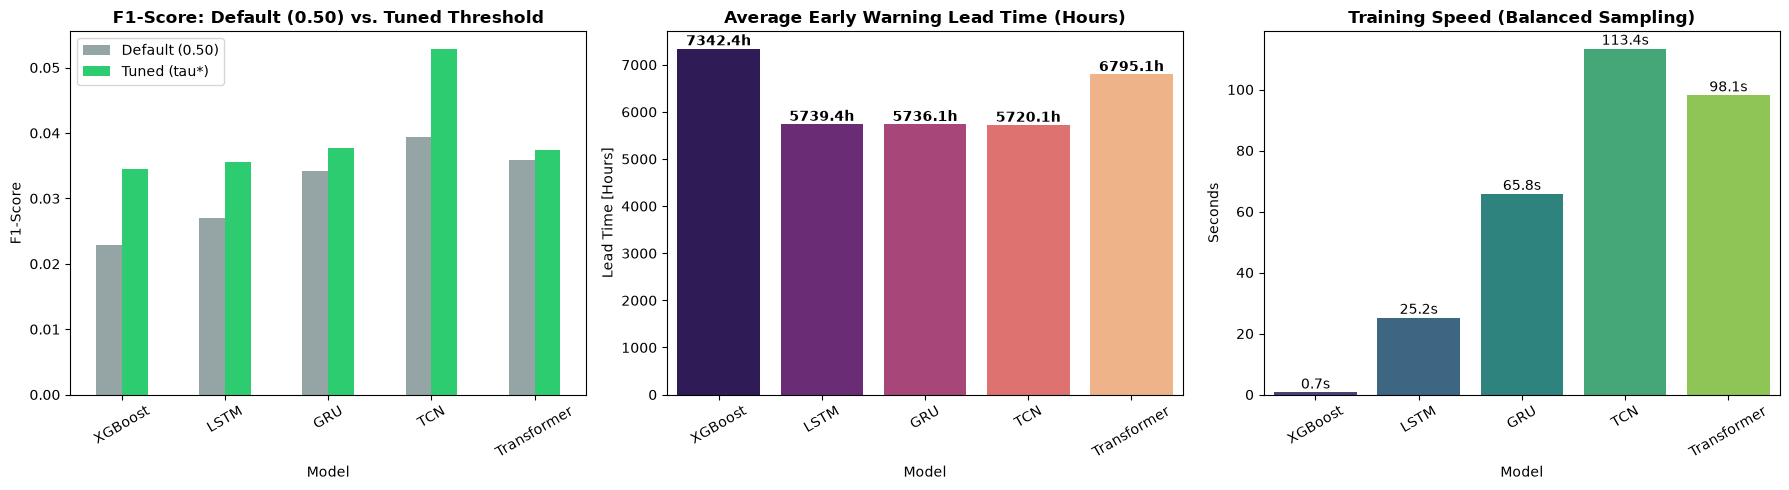

In [10]:
# Visualizing the impact of Threshold Tuning & Comparative Metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: F1-Score comparison before vs after threshold tuning
f1_compare = benchmark_df[['Model', 'Default F1 (0.50)', 'Tuned F1-Score']].set_index('Model')
f1_compare.plot(kind='bar', ax=axes[0], color=['#95a5a6', '#2ecc71'])
axes[0].set_title('F1-Score: Default (0.50) vs. Tuned Threshold', weight='bold')
axes[0].set_ylabel('F1-Score')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(['Default (0.50)', 'Tuned (tau*)'])

# Plot 2: Earliness (Lead time in hours)
sns.barplot(data=benchmark_df, x='Model', y='Avg Earliness (Hours)', palette='magma', ax=axes[1])
axes[1].set_title('Average Early Warning Lead Time (Hours)', weight='bold')
axes[1].set_ylabel('Lead Time [Hours]')
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f}h', (p.get_x() + p.get_width()/2., p.get_height() + 0.5),
                     ha='center', va='bottom', weight='bold')

# Plot 3: Training Duration Benchmark
sns.barplot(data=benchmark_df, x='Model', y='Training Time (s)', palette='viridis', ax=axes[2])
axes[2].set_title('Training Speed (Balanced Sampling)', weight='bold')
axes[2].set_ylabel('Seconds')
axes[2].tick_params(axis='x', rotation=30)
for p in axes[2].patches:
    axes[2].annotate(f'{p.get_height():.1f}s', (p.get_x() + p.get_width()/2., p.get_height() + 0.2),
                     ha='center', va='bottom')

plt.tight_layout()
plt.show()


---
#### Early Warning Telemetry & Anomaly Trajectories
We plot predicted probabilities over **Test Event 0 (Generator Bearing Failure)** to inspect how early each model triggers the alert relative to the failure date.


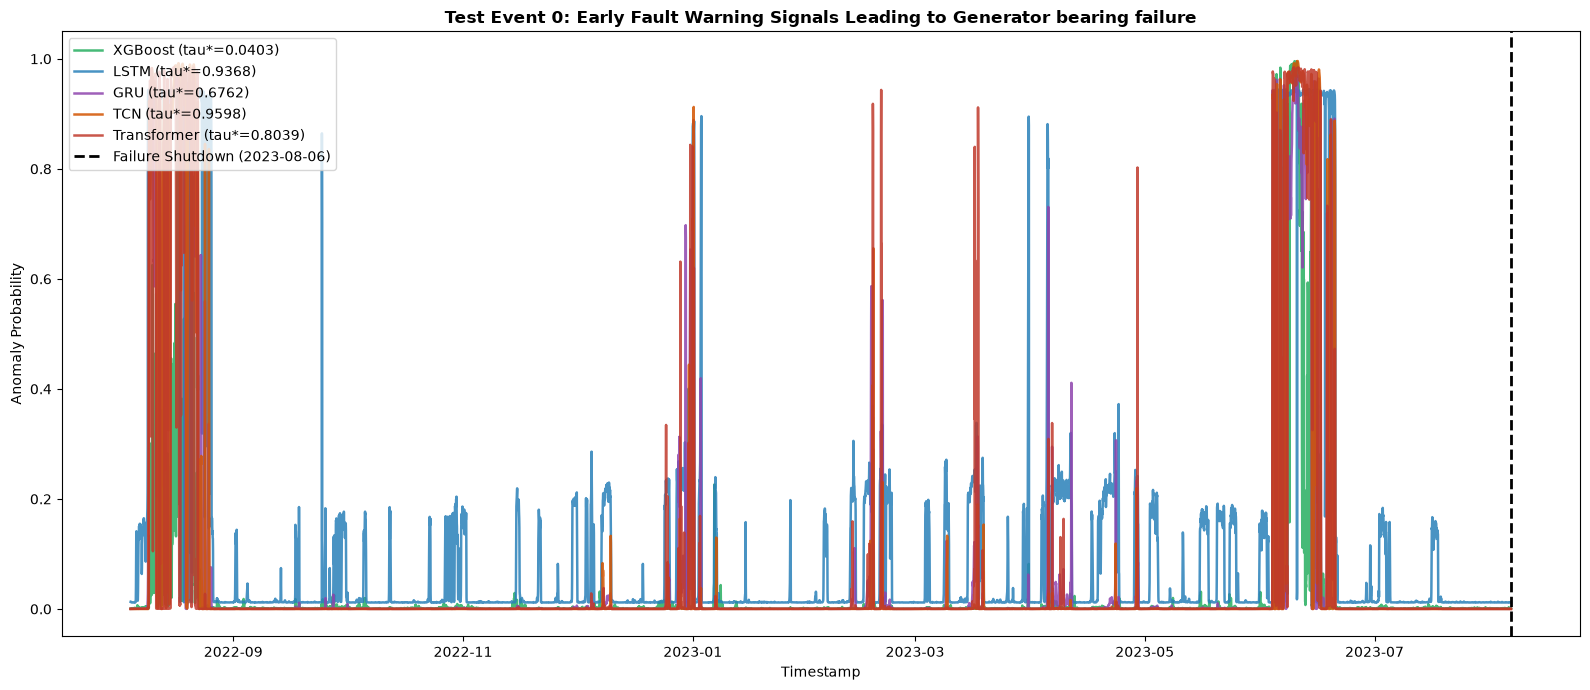

In [11]:
target_evt = 0
evt_0_meta_idx = [i for i, m in enumerate(meta_test) if m[0] == target_evt]
evt_0_times = [pd.to_datetime(meta_test[i][1]) for i in evt_0_meta_idx]

evt_row = event_info[event_info['event_id'] == target_evt].iloc[0]
actual_breakdown = pd.to_datetime(evt_row['event_start'], format='%d.%m.%Y %H:%M')

plt.figure(figsize=(16, 7))
colors = {'XGBoost': '#27ae60', 'LSTM': '#2980b9', 'GRU': '#8e44ad', 'TCN': '#d35400', 'Transformer': '#c0392b'}

for model_name, probs in predictions.items():
    evt_probs = [probs[i] for i in evt_0_meta_idx]
    plt.plot(evt_0_times, evt_probs, label=f'{model_name} (tau*={tuned_thresholds[model_name]})', color=colors[model_name], lw=1.8, alpha=0.85)

plt.axvline(actual_breakdown, color='black', linestyle='--', lw=2, label=f'Failure Shutdown ({actual_breakdown.strftime("%Y-%m-%d")})')
plt.title(f'Test Event {target_evt}: Early Fault Warning Signals Leading to {evt_row["event_description"]}', weight='bold')
plt.xlabel('Timestamp')
plt.ylabel('Anomaly Probability')
plt.ylim(-0.05, 1.05)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


---
#### Summary & Saved Artifacts
#### Artifacts saved to `saved_models/`:
1. **`xgboost_model.json`**: Trained XGBoost model.
2. **`lstm_best.pt`**, **`gru_best.pt`**, **`tcn_best.pt`**, **`transformer_best.pt`**: PyTorch state dicts.
3. **`scaler.joblib`**: StandardScaler instance.
4. **`model_parameters.json`**: Hyperparameters, feature names, and tuned decision thresholds (`tau*`).
5. **`benchmark_results.csv`**: Full comparative leaderboard.
